In [1]:
# conda env 'at3d_pure_k9'
from pathlib import Path
PROJECT_ROOT = Path().resolve().parent
# INTERIM_DATA = PROJECT_ROOT / 'data' / 'interim'

import sys
sys.path.append(str(PROJECT_ROOT))

import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
from src.utils.util import load_sensor_dict, save_sensor_dict, load_config
from scipy.interpolate import interp1d

In [2]:
EXPERIMENT = PROJECT_ROOT / 'experiments' / 'CAMP2Ex_RF17' / 'V08' / 'default'
TAU_1D = EXPERIMENT / 'tau_1D'

config = load_config(EXPERIMENT / 'config.yml')
out_file = TAU_1D / 'TAU_1D_{}.nc'.format(config['obs_file'].stem)

In [3]:
# ## INPUT
# lut_file = PROJECT_ROOT / 'NK1990_1D_Retrieval' / 'LUT_V07.nc'
# obs_file = INTERIM_DATA / 'AT3D_OBS_CAMP2Ex_RF17_default.nc'
# rte_grid_file = INTERIM_DATA / 'RTG_default.nc'

# ## OUTPUT
# out_file = INTERIM_DATA / 'TAU1D_LUT_V07_AT3D_OBS_CAMP2Ex_RF17_default.nc'

In [4]:
rte_grid = xr.load_dataset(config['rte_grid_file'])
obs = load_sensor_dict(config['obs_file'])
Iobs = obs['MISR']['sensor_list'][4].I.data
LUT = xr.load_dataset(TAU_1D / 'LUT_1Dtau.nc')
assert np.all(np.diff(LUT.I.data) > 0), "LUT BRF not monotonic"

tau_interp = interp1d(LUT.I.data, LUT.tau.data, kind='cubic', fill_value='extrapolate')
obs['MISR']['sensor_list'][4]['tau'] = (['nrays'], tau_interp(Iobs))

In [5]:
tau_interp = interp1d(LUT.I.data, LUT.tau.data, kind='cubic', fill_value='extrapolate')
obs['MISR']['sensor_list'][4]['tau'] = (['nrays'], tau_interp(Iobs))
save_sensor_dict(out_file, obs)

Saved sensors to: /data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V08/default/tau_1D/TAU_1D_AT3D_OBS_CAMP2Ex_RF17_default.nc


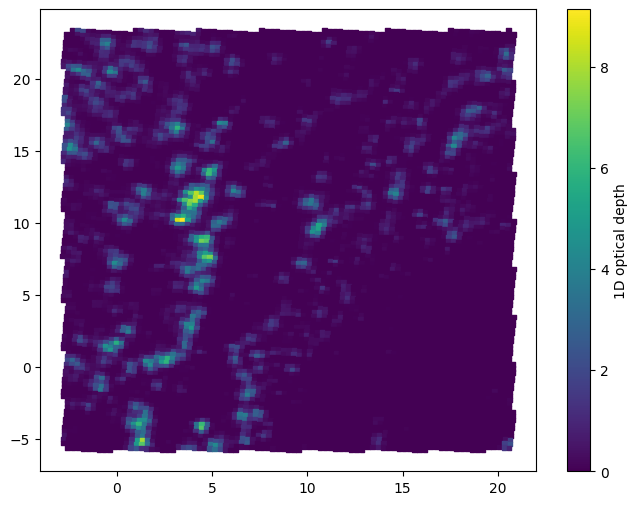

In [6]:
cam = obs['MISR']['sensor_list'][4]
f, ax = plt.subplots(1, 1, figsize=(8,6))
# c = ax.scatter(cam.ray_x, cam.ray_y, c=cam.tau, marker='s', s=10, norm=colors.LogNorm(vmin=0.1, vmax=10))
c = ax.scatter(cam.ray_x, cam.ray_y, c=cam.tau, marker='s', s=10, vmin=0.0, vmax=None)
plt.colorbar(c, label='1D optical depth')